# Investigation 1: Establishing the Category Baseline

We chose products with the exact main category label `Snacks`.

In [42]:
import pandas as pd

columns = [
    "main_category_en",
    "sugars_100g",
    "sodium_100g",
    "ecoscore_grade",
    "fat_100g",
    "brands",
]

df = pd.read_csv("openfoodfacts.csv", usecols=columns)

category = df["main_category_en"].str.strip()
snacks = df.loc[category == "Snacks"].copy()

print("Number of snack records:", len(snacks))
display(snacks.head())

Number of snack records: 33125


,brands,ecoscore_grade,main_category_en,fat_100g,sugars_100g,sodium_100g
593,"Ritter Sport, Alfred Ritter Gmbh & Co",unknown,Snacks,28.00,49.60,0.160
783,Trader Joe's,unknown,Snacks,22.60,6.45,0.774
871,NaN,unknown,Snacks,0.00,75.00,0.000
872,"Welch's, Healthy Food Brands Llc",unknown,Snacks,0.00,64.29,0.000
873,"Welch's, Healthy Food Brands Llc",unknown,Snacks,1.79,78.57,0.000


In [43]:
nutrients = ["sugars_100g", "sodium_100g", "fat_100g"]

for column in nutrients:
    snacks[column] = pd.to_numeric(snacks[column], errors="coerce")
    valid = snacks[column].between(0, 100)
    snacks[column] = snacks[column].where(valid)

print("Missing values after cleaning:")
display(snacks[nutrients].isna().sum())

Missing values after cleaning:


sugars_100g    3
sodium_100g    4
fat_100g       5
dtype: int64

We filtered the data to the snacks category which has 33125 records. We converted sugar and sodium values to numbers and treated values outside 0–100 grams per 100 grams as missing. After cleaning, 3 sugar values and 4 sodium values were missing.

In [44]:
baseline = snacks[["sugars_100g","sodium_100g"]].agg(
    ["count", "mean", "median", "var", "std"]
).T

baseline = baseline.rename(columns={
    "var": "variance",
    "std": "standard deviation"
})

display(baseline.round(6))

,count,mean,median,variance,standard deviation
sugars_100g,33122.0,18.436009,9.38000,378.583679,19.457227
sodium_100g,33121.0,0.446133,0.32172,0.518955,0.720385


Among products labeled Snacks, sugar had a standard deviation of 19.46 g per 100 g, and sodium had a standard deviation of 0.72 g per 100 g. Both varied across products in the same category, so shoppers could pick a snack with more sugar or sodium than they expect. Comparing nutrition labels per 100 g makes it easier to judge products with different serving sizes.

In [45]:
sugar = snacks["sugars_100g"].dropna()

q25 = sugar.quantile(0.25)
q50 = sugar.quantile(0.50)
q75 = sugar.quantile(0.75)

print(f"25th percentile: {q25:g} g per 100 g")
print(f"50th percentile: {q50:g} g per 100 g")
print(f"75th percentile: {q75:g} g per 100 g")
print(f"75th percentile minus median: {q75 - q50:g} g per 100 g")
print(f"Share at or below the cutoff: {(sugar <= q25).mean():.1%}")

25th percentile: 3.57 g per 100 g
50th percentile: 9.38 g per 100 g
75th percentile: 31.11 g per 100 g
75th percentile minus median: 21.73 g per 100 g
Share at or below the cutoff: 36.3%


Parent guide: Choose snacks with 3.57 g of sugar or less per 100 g. This is the 25th percentile, but 36.3% of snacks with sugar data meet the cutoff because many have exactly 3.57 g.

Higher-sugar snacks: Yes, the top 75th percentile is 31.11 g of sugar per 100 g. That’s 21.73 g more than the median of 9.38 g per 100 g, so the difference is substantial.

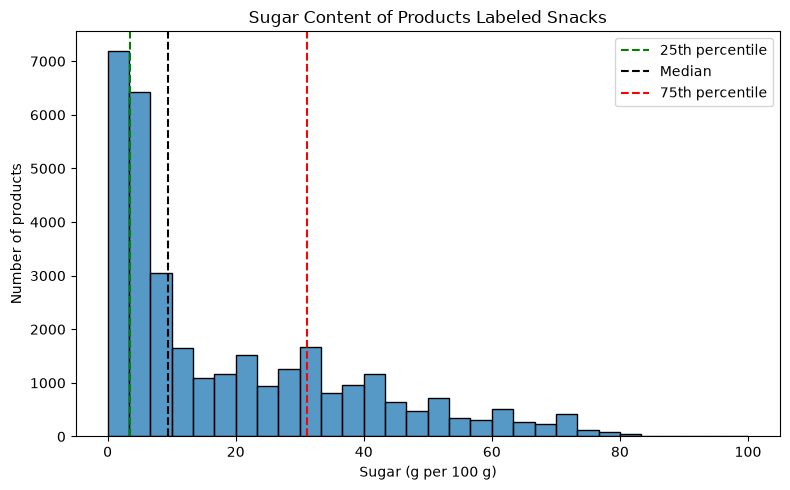

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.histplot(x=sugar, bins=30)

plt.axvline(q25, color="green", linestyle="--", label="25th percentile")
plt.axvline(q50, color="black", linestyle="--", label="Median")
plt.axvline(q75, color="red", linestyle="--", label="75th percentile")

plt.title("Sugar Content of Products Labeled Snacks")
plt.xlabel("Sugar (g per 100 g)")
plt.ylabel("Number of products")
plt.legend()
plt.tight_layout()

The histogram is skewed to the right, with many snacks clustered at low sugar levels and fewer at higher levels.

## Investigation 2

Do sweet snacks with Eco-score grades A or B have lower average sodium
than sweet snacks with grades D or E?

All 33,125 products with the exact `Snacks` label had unknown Eco-scores.
We used the `Snacks-sucres` category because it had usable sodium values
in both Eco-score groups.

- **Null hypothesis** — The two groups have the same mean sodium content.
- **Alternative hypothesis** — The A/B group has lower mean sodium than the D/E group.
- **Significance level** — 0.05.

In [47]:
category = df["main_category_en"].str.strip()
sweet_snacks = df.loc[
    category.eq("Snacks-sucres"), ["ecoscore_grade", "sodium_100g"]
].copy()

grades = sweet_snacks["ecoscore_grade"].astype("string").str.strip().str.upper()
sodium = pd.to_numeric(sweet_snacks["sodium_100g"], errors="coerce")
valid_sodium = sodium.between(0, 100)

# Convert grams to milligrams per 100 g.
eco_friendly = sodium.loc[grades.isin(["A", "B"]) & valid_sodium] * 1000
eco_harmful = sodium.loc[grades.isin(["D", "E"]) & valid_sodium] * 1000

observed_difference = eco_friendly.mean() - eco_harmful.mean()

print(f"A/B group: {len(eco_friendly)} snacks")
print(f"D/E group: {len(eco_harmful)} snacks")
print(f"A/B mean sodium: {eco_friendly.mean():.2f} mg per 100 g")
print(f"D/E mean sodium: {eco_harmful.mean():.2f} mg per 100 g")
print(f"A/B minus D/E: {observed_difference:.2f} mg per 100 g")

A/B group: 91 snacks
D/E group: 48 snacks
A/B mean sodium: 204.74 mg per 100 g
D/E mean sodium: 177.78 mg per 100 g
A/B minus D/E: 26.95 mg per 100 g


In [48]:
import numpy as np

rng = np.random.default_rng(105)
pooled_sodium = np.concatenate([eco_friendly.to_numpy(), eco_harmful.to_numpy()])
friendly_count = len(eco_friendly)
num_shuffles = 10_000
as_low_or_lower = 0

for _ in range(num_shuffles):
    shuffled = rng.permutation(pooled_sodium)
    shuffled_difference = (
        shuffled[:friendly_count].mean()
        - shuffled[friendly_count:].mean()
    )
    if shuffled_difference <= observed_difference:
        as_low_or_lower += 1

p_value = (as_low_or_lower + 1) / (num_shuffles + 1)
print(f"One-sided p-value: {p_value:.6f}")

One-sided p-value: 0.792721


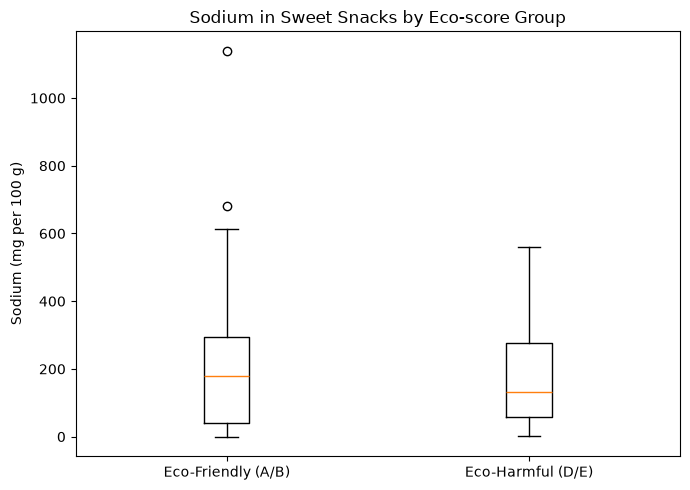

In [49]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

ax.boxplot([eco_friendly, eco_harmful])
ax.set_xticks([1, 2])
ax.set_xticklabels(["Eco-Friendly (A/B)", "Eco-Harmful (D/E)"])
ax.set_ylabel("Sodium (mg per 100 g)")
ax.set_title("Sodium in Sweet Snacks by Eco-score Group")

plt.tight_layout()

### Investigation 2 Conclusion

Sweet snacks with A/B Eco-scores had an average of 204.74 mg of sodium per 100 g. Sweet snacks with D/E scores averaged 177.78 mg per 100 g. That means the A/B group had 26.95 mg more sodium per 100 g on average.

The permutation test gave a p-value of 0.792721. Since that is above 0.05, we failed to reject the null hypothesis. We didn’t find enough evidence to say that sweet snacks with better Eco-scores have less sodium.

# Investigation 3

In [50]:
fat_sugar = snacks[["fat_100g", "sugars_100g"]].dropna()

covariance = fat_sugar["fat_100g"].cov(fat_sugar["sugars_100g"])
overall_r = fat_sugar["fat_100g"].corr(fat_sugar["sugars_100g"])

print(f"Snack records with both measurements: {len(fat_sugar):,}")
print(f"Covariance: {covariance:.3f}")
print(f"Pearson correlation: {overall_r:.3f}")

Snack records with both measurements: 33,120
Covariance: -137.355
Pearson correlation: -0.413


Across 33,120 snack records, the covariance between fat and sugar was −137.355, and the Pearson correlation was −0.413. Snacks with less fat tended to have more sugar, suggesting a moderate trade-off across the category. This pattern alone can’t tell us whether manufacturers deliberately added sugar when reducing fat.

In [51]:
brand_data = snacks[["brands", "fat_100g", "sugars_100g"]].dropna().copy()

# Clean brand names and combine labels that differ only in capitalization.
brand_data["brands"] = brand_data["brands"].str.strip().str.casefold()

# Keep records with a single, known brand.
brand_data = brand_data[
    brand_data["brands"].ne("")
    & brand_data["brands"].ne("unknown")
    & ~brand_data["brands"].str.contains(",", regex=False)
]

top_brands = brand_data["brands"].value_counts().head(3)
brand_results = []

for brand in top_brands.index:
    products = brand_data[brand_data["brands"] == brand]

    brand_results.append({
        "Brand": brand,
        "Records": len(products),
        "Correlation": products["fat_100g"].corr(products["sugars_100g"]),
    })

brand_summary = pd.DataFrame(brand_results)
display(brand_summary.round(3))

,Brand,Records,Correlation
0,meijer,204,-0.526
1,utz,140,-0.159
2,roundy's,138,-0.333


The negative relationship between fat and sugar was strongest for Meijer r=-0.526, followed by Roundy’s r=-0.333 and Utz r=-0.159. Compared with snacks overall r=-0.413, the pattern was stronger for Meijer and weaker for Roundy’s and Utz. Shoppers choosing a low-fat snack should also check the sugar per 100 g, especially when comparing Meijer products. Differences in the types of snacks each brand sells could help explain the pattern.

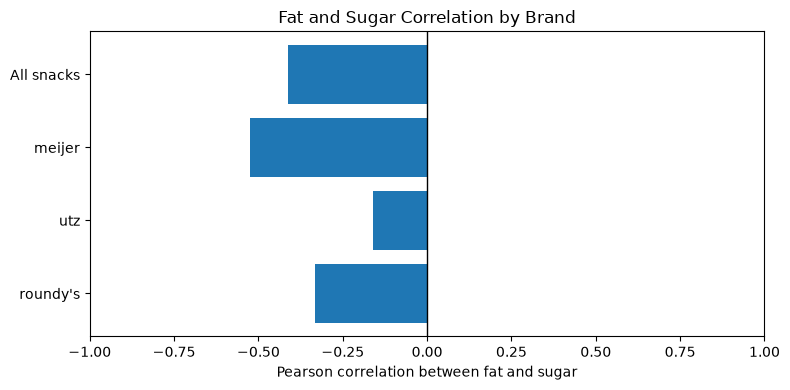

In [52]:
comparison = pd.concat([
    pd.DataFrame({"Brand": ["All snacks"], "Correlation": [overall_r]}),
    brand_summary[["Brand", "Correlation"]],
], ignore_index=True)

plt.figure(figsize=(8, 4))
plt.barh(comparison["Brand"], comparison["Correlation"])
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1, 1)
plt.gca().invert_yaxis()
plt.xlabel("Pearson correlation between fat and sugar")
plt.title("Fat and Sugar Correlation by Brand")
plt.tight_layout()